# [IAPD] TP1 - ETL

**Alumno:** Nicolás Druetta.

**Materia:** Procesamiento de Datos.

**Dataset:** Evolución histórica de los principales índices bursátiles de 18 países (2006-2026).

**Fuente:** Yahoo Finance (`yfinance`). Datos descargados previamente y almacenados en un archivo CSV.

## Preguntas que busco responder:

1. ¿Cuáles fueron los años con mayor crecimiento y mayores pérdidas para cada índice bursátil?
2. ¿Qué mercados bursátiles obtuvieron el mayor rendimiento acumulado durante los últimos 20 años?
3. ¿Los índices bursátiles de un mismo continente muestran tendencias similares?
4. ¿Qué diferencias existen entre los mercados bursátiles de países desarrollados y emergentes?
5. ¿Cuáles son los mercados bursátiles que muestran una tendencia de crecimiento más favorable en los últimos años?
6. ¿Existen patrones estacionales en el volumen de operaciones bursátiles?

## 1.&nbsp;Preparación previa

### 1.1. Importo las librerías necesarias para trabajar.

In [1]:
# Importo las librerías necesarias para trabajar.
import matplotlib.pyplot as plt
import pandas as pd
import plotly.graph_objects as go

from IPython.display import HTML, display

### 1.2. Selecciono los índices bursátiles que voy a investigar.

In [2]:
# Defino los 18 índices bursátiles que voy a investigar, con sus nombres y símbolos de Yahoo Finance.
indices = {
    "Alemania": ("DAX 40", "^GDAXI"),
    "Australia": ("S&P/ASX 200", "^AXJO"),
    "Brasil": ("Ibovespa", "^BVSP"),
    "Canadá": ("S&P/TSX Composite", "^GSPTSE"),
    "China": ("Shanghai Composite", "000001.SS"),
    "Corea del Sur": ("KOSPI Composite", "^KS11"),
    "España": ("IBEX 35", "^IBEX"),
    "Estados Unidos": ("S&P 500", "^GSPC"),
    "Francia": ("CAC 40", "^FCHI"),
    "Hong Kong": ("Hang Seng", "^HSI"),
    "India": ("BSE Sensex", "^BSESN"),
    "Japón": ("Nikkei 225", "^N225"),
    "México": ("S&P/BMV IPC", "^MXX"),
    "Nueva Zelanda": ("S&P/NZX 50", "^NZ50"),
    "Países Bajos": ("AEX", "^AEX"),
    "Reino Unido": ("FTSE 100", "^FTSE"),
    "Suiza": ("SMI", "^SSMI"),
    "Taiwán": ("TAIEX", "^TWII")
}

### 1.3. Creo estilo visual para títulos en HTML.

In [3]:
# Defino los estilos para los títulos.
style = """
<style>
    label {
        color: #333;
        display: block;
        margin: 0 0 5px 0;
        font-family: "Trebuchet MS", sans-serif;
        font-size: 16px;
        font-weight: bold;
        line-height: 1.2;
    }
    hr {
        border: 1px solid #333;
        border-bottom: none;
        display: block;
        margin: 0 0 15px 0;
        font-weight: bold;
        width: 95%;
    }
</style>
"""

# Defino una función para mostrar títulos en HTML.
def title(texto):
    display(HTML(f"{style}<label>{texto}</label><hr/>"))

## 2.&nbsp;Arquitectura Medallion

### 2.1. Capa Bronze (ingesta en crudo)

In [4]:
# Cargo los datos históricos desde el archivo local.
file_path = "data/indices_bursatiles.csv"

df_bronze = pd.read_csv(
    file_path,
    header=[0, 1],
    index_col=0,
    parse_dates=[0]
)

# Muestro la estructura del dataset.
title("Estructura general del dataset:")
print(f"Archivo cargado: {file_path}.")
print(f"Filas: {df_bronze.shape[0]}.")
print(f"Columnas: {df_bronze.shape[1]}.")
print(f"Formato ancho: {df_bronze.shape[1]} columnas en Bronze.")

Archivo cargado: data/indices_bursatiles.csv.
Filas: 5208.
Columnas: 108.
Formato ancho: 108 columnas en Bronze.


In [5]:
# Obtengo los nombres completos de las columnas originales.
columnas_originales = ", ".join(f"{variable} ({ticker})" for variable, ticker in df_bronze.columns)

# Muestro las columnas que descargué de Yahoo Finance.
title("Columnas originales:")
display(HTML(f"<div style='width:95%;'>{columnas_originales}</div>"))

> Veo que Yahoo Finance devuelve los datos en formato ancho, con columnas de dos niveles (**MultiIndex**). En el primero aparecen las variables bursátiles (Adj Close, Close, High, Low, Open y Volume) y en el segundo, el ticker de cada índice. Como tengo 18 índices y 6 variables por cada uno, en total tengo 108 columnas.

In [6]:
# Creo un resumen de la cobertura histórica de cada índice bursátil.
resumen = []

for pais, (nombre, ticker) in indices.items():
    precios = df_bronze["Close"][ticker].dropna()
    volumen = df_bronze["Volume"][ticker].dropna()

    resumen.append({
        "País": pais,
        "Índice": nombre,
        "Ticker": ticker,
        "Fecha mínima": precios.index.min() if not precios.empty else pd.NaT,
        "Fecha máxima": precios.index.max() if not precios.empty else pd.NaT,
        "Velas": len(precios),
        "Velas con volumen": int((volumen > 0).sum())
    })

# Convierto el resumen en un DataFrame.
df_resumen = pd.DataFrame(resumen)

# Muestro la cobertura histórica ordenada por país.
title("Cobertura de índices bursátiles internacionales:")
display(df_resumen.sort_values("País"))

,País,Índice,Ticker,Fecha mínima,Fecha máxima,Velas,Velas con volumen
0,Alemania,DAX 40,^GDAXI,2006-11-17,2026-11-17,5073,5060
1,Australia,S&P/ASX 200,^AXJO,2006-11-17,2026-11-17,5051,2349
2,Brasil,Ibovespa,^BVSP,2006-11-17,2026-11-17,4952,4892
3,Canadá,S&P/TSX Composite,^GSPTSE,2006-11-17,2026-11-17,5019,5016
4,China,Shanghai Composite,000001.SS,2006-11-17,2026-11-17,4855,4855
5,Corea del Sur,KOSPI Composite,^KS11,2006-11-17,2026-11-17,4923,4921
6,España,IBEX 35,^IBEX,2006-11-17,2026-11-17,5106,4853
7,Estados Unidos,S&P 500,^GSPC,2006-11-17,2026-11-17,5030,5029
8,Francia,CAC 40,^FCHI,2006-11-17,2026-11-17,5112,5035
9,Hong Kong,Hang Seng,^HSI,2006-11-17,2026-11-17,4923,4920


> Me hubiera gustado incluir a **Argentina**, pero Yahoo Finance solo tiene datos históricos de precios y no cuenta con suficientes datos de volumen para el análisis. Por eso, elegí a Brasil como representante de Sudamérica. También quise incluir a Sudáfrica para representar al continente africano, pero tampoco encontré suficientes datos históricos en Yahoo Finance.

In [7]:
# Analizo la calidad de los datos descargados por índice bursátil.
calidad = []

for pais, (nombre, ticker) in indices.items():
    datos = df_bronze["Close"][ticker]

    calidad.append({
        "País": pais,
        "Índice": nombre,
        "Ticker": ticker,
        "Registros": len(datos),
        "Válidos": int(datos.notna().sum()),
        "Nulos": int(datos.isna().sum()),
        "Cobertura (%)": round(datos.notna().mean() * 100, 2),
        "Duplicados": int(datos.index.duplicated().sum())
    })

# Convierto los resultados en un DataFrame.
df_calidad = pd.DataFrame(calidad)

# Muestro el reporte de calidad ordenado por país.
title("Calidad de los datos por índice bursátil:")
display(df_calidad.sort_values("País"))

,País,Índice,Ticker,Registros,Válidos,Nulos,Cobertura (%),Duplicados
0,Alemania,DAX 40,^GDAXI,5208,5073,135,97.41,0
1,Australia,S&P/ASX 200,^AXJO,5208,5051,157,96.99,0
2,Brasil,Ibovespa,^BVSP,5208,4952,256,95.08,0
3,Canadá,S&P/TSX Composite,^GSPTSE,5208,5019,189,96.37,0
4,China,Shanghai Composite,000001.SS,5208,4855,353,93.22,0
5,Corea del Sur,KOSPI Composite,^KS11,5208,4923,285,94.53,0
6,España,IBEX 35,^IBEX,5208,5106,102,98.04,0
7,Estados Unidos,S&P 500,^GSPC,5208,5030,178,96.58,0
8,Francia,CAC 40,^FCHI,5208,5112,96,98.16,0
9,Hong Kong,Hang Seng,^HSI,5208,4923,285,94.53,0


In [8]:
# Valido si existen fechas duplicadas en el dataset original.
title("Validación de fechas:")
print(f"Fechas duplicadas: {df_bronze.index.duplicated().sum()}")
print(f"Fechas sin datos de cierre en ningún índice: {df_bronze['Close'].isna().all(axis=1).sum()}")

Fechas duplicadas: 0
Fechas sin datos de cierre en ningún índice: 0


> Veo que los 18 índices tienen una buena cobertura de datos, todos por encima del 93 %, y no encontré fechas duplicadas. También aparecen valores nulos, pero esto puede deberse a que las bolsas de cada país tienen distintos feriados y días de operación. Voy a tenerlo en cuenta cuando limpie los datos en Silver.

### 2.2. Capa Silver (limpieza y transformación)

In [9]:
# Convierto los datos de Bronze de formato ancho a largo, sin modificar el original.
df_silver = df_bronze.stack(level=1, future_stack=True).reset_index()

# Quito el nombre del eje de columnas.
df_silver.columns.name = None

# Muestro los primeros registros y la cantidad de columnas.
title("Datos de la capa Silver:")
display(df_silver)
print()
print(f"Formato largo: {df_silver.shape[1]} columnas en Silver.")

,Date,Ticker,Adj Close,Close,High,Low,Open,Volume
0,2006-11-17,000001.SS,1971.792969,1971.792969,1972.607056,1925.149048,1934.636963,49400.0
1,2006-11-17,^AEX,492.619995,492.619995,496.429993,490.980011,495.549988,146892300.0
2,2006-11-17,^AXJO,5419.700195,5419.700195,5426.000000,5356.899902,5385.200195,0.0
3,2006-11-17,^BSESN,13429.480469,13429.480469,13678.040039,13383.429688,13678.040039,20800.0
4,2006-11-17,^BVSP,41029.000000,41029.000000,41164.000000,40482.000000,41164.000000,0.0
...,...,...,...,...,...,...,...,...
93739,2026-11-17,^MXX,70388.960938,70388.960938,71446.671875,70307.359375,71106.023438,172011187.0
93740,2026-11-17,^N225,58860.429688,58860.429688,59369.140625,58691.109375,59295.800781,138500000.0
93741,2026-11-17,^NZ50,14295.530273,14295.530273,14351.150391,14287.099609,14306.959961,97561600.0
93742,2026-11-17,^SSMI,14976.040039,14976.040039,15159.269531,14956.599609,15142.660156,21731700.0



Formato largo: 8 columnas en Silver.


> Los datos de Yahoo Finance vienen en **formato ancho**, con una fila por fecha y varias columnas para cada índice. Como trabajo con 18 índices, tengo 108 columnas en Bronze.
>
> En Silver paso los datos a **formato largo**, donde cada fila corresponde a una fecha y un índice bursátil. Así paso de 108 a 8 columnas y me resulta más fácil trabajar con los datos.

In [10]:
# Creo una copia para incorporar el país y el nombre de cada índice bursátil.
df_silver_indices = df_silver.copy()

# Relaciono cada ticker con su país y el nombre del índice.
datos_indices = {
    ticker: (pais, nombre)
    for pais, (nombre, ticker) in indices.items()
}

# Agrego las columnas de país e índice.
df_silver_indices["País"] = df_silver_indices["Ticker"].map(lambda ticker: datos_indices[ticker][0])
df_silver_indices["Índice"] = df_silver_indices["Ticker"].map(lambda ticker: datos_indices[ticker][1])

# Muestro los primeros registros.
title("Índices bursátiles identificados por país:")
display(df_silver_indices)

,Date,Ticker,Adj Close,Close,High,Low,Open,Volume,País,Índice
0,2006-11-17,000001.SS,1971.792969,1971.792969,1972.607056,1925.149048,1934.636963,49400.0,China,Shanghai Composite
1,2006-11-17,^AEX,492.619995,492.619995,496.429993,490.980011,495.549988,146892300.0,Países Bajos,AEX
2,2006-11-17,^AXJO,5419.700195,5419.700195,5426.000000,5356.899902,5385.200195,0.0,Australia,S&P/ASX 200
3,2006-11-17,^BSESN,13429.480469,13429.480469,13678.040039,13383.429688,13678.040039,20800.0,India,BSE Sensex
4,2006-11-17,^BVSP,41029.000000,41029.000000,41164.000000,40482.000000,41164.000000,0.0,Brasil,Ibovespa
...,...,...,...,...,...,...,...,...,...,...
93739,2026-11-17,^MXX,70388.960938,70388.960938,71446.671875,70307.359375,71106.023438,172011187.0,México,S&P/BMV IPC
93740,2026-11-17,^N225,58860.429688,58860.429688,59369.140625,58691.109375,59295.800781,138500000.0,Japón,Nikkei 225
93741,2026-11-17,^NZ50,14295.530273,14295.530273,14351.150391,14287.099609,14306.959961,97561600.0,Nueva Zelanda,S&P/NZX 50
93742,2026-11-17,^SSMI,14976.040039,14976.040039,15159.269531,14956.599609,15142.660156,21731700.0,Suiza,SMI


> **Close** es el precio de cierre original, mientras que **Adj Close** es el precio de cierre ajustado por eventos corporativos, como dividendos y divisiones de acciones (stock splits), cuando corresponde.

In [11]:
# Creo una copia para ordenar las columnas del dataset.
df_silver_ordenado = df_silver_indices.copy()

# Defino el orden de las columnas.
columnas = ["Date", "País", "Índice", "Ticker", "Open", "High", "Low", "Close", "Adj Close", "Volume"]

# Organizo las columnas sin modificar el DataFrame anterior.
df_silver_ordenado = df_silver_ordenado[columnas].sort_values(["País", "Date"]).copy()

# Muestro los primeros registros ordenados por país y fecha.
title("Columnas organizadas de la capa Silver:")
display(df_silver_ordenado)

,Date,País,Índice,Ticker,Open,High,Low,Close,Adj Close,Volume
7,2006-11-17,Alemania,DAX 40,^GDAXI,6438.180176,6451.689941,6398.520020,6412.359863,6412.359863,133523800.0
25,2006-11-20,Alemania,DAX 40,^GDAXI,6394.080078,6459.529785,6368.069824,6452.330078,6452.330078,96175500.0
43,2006-11-21,Alemania,DAX 40,^GDAXI,6450.560059,6476.709961,6447.529785,6460.390137,6460.390137,81401700.0
61,2006-11-22,Alemania,DAX 40,^GDAXI,6475.299805,6497.060059,6453.490234,6476.129883,6476.129883,91235800.0
79,2006-11-23,Alemania,DAX 40,^GDAXI,6483.580078,6494.700195,6461.580078,6475.250000,6475.250000,65858500.0
...,...,...,...,...,...,...,...,...,...,...
93671,2026-11-11,Taiwán,TAIEX,^TWII,43135.761719,44257.148438,42708.050781,44257.148438,44257.148438,4012900.0
93689,2026-11-12,Taiwán,TAIEX,^TWII,44180.460938,44525.238281,42943.500000,43091.871094,43091.871094,5242800.0
93707,2026-11-13,Taiwán,TAIEX,^TWII,43719.750000,44489.480469,43534.121094,43675.121094,43675.121094,4605600.0
93725,2026-11-16,Taiwán,TAIEX,^TWII,43512.421875,43512.421875,41040.078125,41040.078125,41040.078125,4285200.0


> Dejo los nombres originales de Yahoo Finance en inglés para reconocerlos más fácilmente. Las columnas que agrego y los resultados del análisis los presento en español.

In [12]:
# Reviso cuántos valores nulos tiene cada columna.
df_silver_nulos = df_silver_ordenado.isnull().sum().reset_index()
df_silver_nulos.columns = ["Columna", "Nulos"]

# Calculo el porcentaje de valores nulos sobre el total de registros.
df_silver_nulos["Porcentaje (%)"] = (df_silver_nulos["Nulos"] / len(df_silver_ordenado) * 100).round(2)

# Muestro los resultados.
title("Valores nulos de la capa Silver:")
display(df_silver_nulos)

,Columna,Nulos,Porcentaje (%)
0,Date,0,0.00
1,País,0,0.00
2,Índice,0,0.00
3,Ticker,0,0.00
4,Open,3888,4.15
5,High,3888,4.15
6,Low,3888,4.15
7,Close,3888,4.15
8,Adj Close,3888,4.15
9,Volume,3888,4.15


> Encontré valores nulos en los datos, pero antes de eliminarlos quiero revisar de dónde vienen y si corresponden a días en los que las bolsas no operaron.

In [13]:
# Creo una copia con los registros que no tienen precio de cierre.
df_resumen_dias_nulos = df_silver_ordenado[df_silver_ordenado["Close"].isna()].copy()

# Defino los nombres de los días de lunes a viernes.
dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes"
}

# Identifico el día de la semana de cada registro.
df_resumen_dias_nulos["Día"] = df_resumen_dias_nulos["Date"].dt.day_of_week.map(dias)

# Agrupo los registros sin cotización por país y día de la semana.
df_resumen_dias_nulos = df_resumen_dias_nulos.groupby(
    ["País", "Día"]
).size().unstack(fill_value=0)

# Ordeno las columnas de lunes a viernes.
df_resumen_dias_nulos = df_resumen_dias_nulos.reindex(columns=list(dias.values()), fill_value=0)

# Calculo el total de registros sin cotización por país.
df_resumen_dias_nulos["Total"] = df_resumen_dias_nulos.sum(axis=1)

# Muestro los resultados.
title("Registros sin cotización por país y día de la semana (lunes a viernes):")
display(df_resumen_dias_nulos.sort_index())

Día,Lunes,Martes,Miércoles,Jueves,Viernes,Total
País,,,,,,
Alemania,45,17,19,18,36,135
Australia,76,18,15,15,33,157
Brasil,58,51,35,53,59,256
Canadá,124,14,12,9,30,189
China,95,62,57,62,77,353
Corea del Sur,71,49,63,44,58,285
España,33,9,13,12,35,102
Estados Unidos,98,7,10,29,34,178
Francia,32,9,11,11,33,96


> Para este análisis solo tengo en cuenta los días de lunes a viernes, ya que las bolsas no operan los fines de semana. Los días sin cotización pueden deberse a los feriados bursátiles de cada país.

In [14]:
# Defino las columnas bursátiles que voy a revisar.
columnas_precios = ["Adj Close", "Close", "High", "Low", "Open", "Volume"]

# Defino los nombres de los días de la semana.
dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes"
}

# Identifico los días de semana que no tienen ningún dato bursátil.
df_silver_sin_cotizacion = df_silver_ordenado[
    df_silver_ordenado[columnas_precios].isna().all(axis=1)
].copy()

# Identifico los días de semana que tienen algunos datos faltantes.
df_silver_incompletos = df_silver_ordenado[
    df_silver_ordenado[columnas_precios].isna().any(axis=1)
    & ~df_silver_ordenado[columnas_precios].isna().all(axis=1)
].copy()

# Agrego el día de la semana después de la fecha.
df_silver_sin_cotizacion.insert(
    1,
    "Día",
    df_silver_sin_cotizacion["Date"].dt.day_of_week.map(dias)
)

# Muestro la cantidad de registros encontrados.
title("Validación de datos bursátiles:")
print(f"Registros con todos los datos vacíos: {len(df_silver_sin_cotizacion)}")
print(f"Registros con algunos datos faltantes: {len(df_silver_incompletos)}")
print()

# Muestro los registros que tienen todas las variables bursátiles vacías.
title("Registros con todos los datos vacíos:")
display(df_silver_sin_cotizacion)

Registros con todos los datos vacíos: 3888
Registros con algunos datos faltantes: 0



,Date,Día,País,Índice,Ticker,Open,High,Low,Close,Adj Close,Volume
475,2006-12-25,Lunes,Alemania,DAX 40,^GDAXI,NaN,NaN,NaN,NaN,NaN,NaN
493,2006-12-26,Martes,Alemania,DAX 40,^GDAXI,NaN,NaN,NaN,NaN,NaN,NaN
1789,2007-04-06,Viernes,Alemania,DAX 40,^GDAXI,NaN,NaN,NaN,NaN,NaN,NaN
1807,2007-04-09,Lunes,Alemania,DAX 40,^GDAXI,NaN,NaN,NaN,NaN,NaN,NaN
2095,2007-05-01,Martes,Alemania,DAX 40,^GDAXI,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
93077,2026-09-25,Viernes,Taiwán,TAIEX,^TWII,NaN,NaN,NaN,NaN,NaN,NaN
93095,2026-09-28,Lunes,Taiwán,TAIEX,^TWII,NaN,NaN,NaN,NaN,NaN,NaN
93257,2026-10-09,Viernes,Taiwán,TAIEX,^TWII,NaN,NaN,NaN,NaN,NaN,NaN
93437,2026-10-23,Viernes,Taiwán,TAIEX,^TWII,NaN,NaN,NaN,NaN,NaN,NaN


> Encontré 3.906 registros con todos los datos vacíos debido a días sin actividad bursátil, como Navidad, Año Nuevo y los feriados de cada país. No encontré registros con datos parcialmente incompletos, así que voy a eliminar las filas vacías.

In [15]:
# Creo una copia sin los registros que tienen todos los datos bursátiles vacíos.
df_silver_depurado = df_silver_ordenado.dropna(subset=columnas_precios, how="all").copy()

# Reviso cuántos registros eliminé y cuántos conservé.
title("Depuración de registros vacíos:")
print(f"Registros originales: {len(df_silver_ordenado)}")
print(f"Registros eliminados: {len(df_silver_ordenado) - len(df_silver_depurado)}")
print(f"Registros conservados: {len(df_silver_depurado)}")
print()

# Muestro los registros del dataset depurado.
title("Datos depurados de la capa Silver:")
display(df_silver_depurado)

Registros originales: 93744
Registros eliminados: 3888
Registros conservados: 89856



,Date,País,Índice,Ticker,Open,High,Low,Close,Adj Close,Volume
7,2006-11-17,Alemania,DAX 40,^GDAXI,6438.180176,6451.689941,6398.520020,6412.359863,6412.359863,133523800.0
25,2006-11-20,Alemania,DAX 40,^GDAXI,6394.080078,6459.529785,6368.069824,6452.330078,6452.330078,96175500.0
43,2006-11-21,Alemania,DAX 40,^GDAXI,6450.560059,6476.709961,6447.529785,6460.390137,6460.390137,81401700.0
61,2006-11-22,Alemania,DAX 40,^GDAXI,6475.299805,6497.060059,6453.490234,6476.129883,6476.129883,91235800.0
79,2006-11-23,Alemania,DAX 40,^GDAXI,6483.580078,6494.700195,6461.580078,6475.250000,6475.250000,65858500.0
...,...,...,...,...,...,...,...,...,...,...
93671,2026-11-11,Taiwán,TAIEX,^TWII,43135.761719,44257.148438,42708.050781,44257.148438,44257.148438,4012900.0
93689,2026-11-12,Taiwán,TAIEX,^TWII,44180.460938,44525.238281,42943.500000,43091.871094,43091.871094,5242800.0
93707,2026-11-13,Taiwán,TAIEX,^TWII,43719.750000,44489.480469,43534.121094,43675.121094,43675.121094,4605600.0
93725,2026-11-16,Taiwán,TAIEX,^TWII,43512.421875,43512.421875,41040.078125,41040.078125,41040.078125,4285200.0


In [16]:
# Compruebo si quedaron valores nulos después de la limpieza.
nulos = df_silver_depurado.isna().sum().sum()

# Compruebo si hay fechas duplicadas para un mismo índice bursátil.
duplicados = df_silver_depurado.duplicated(subset=["Date", "Ticker"]).sum()

# Muestro los resultados de la validación.
title("Validación final de los datos depurados:")
print(f"Registros conservados: {len(df_silver_depurado)}")
print(f"Valores nulos restantes: {nulos}")
print(f"Fechas duplicadas por índice: {duplicados}")

Registros conservados: 89856
Valores nulos restantes: 0
Fechas duplicadas por índice: 0


In [17]:
# Defino las columnas de precios que voy a validar.
columnas_precios = ["Adj Close", "Close", "High", "Low", "Open"]

# Compruebo que los precios sean positivos y que el volumen no sea negativo.
precios_invalidos = (df_silver_depurado[columnas_precios] <= 0).any(axis=1).sum()
volumen_invalido = (df_silver_depurado["Volume"] < 0).sum()

# Compruebo que los precios máximos y mínimos sean coherentes.
maximos_invalidos = (df_silver_depurado["High"] < df_silver_depurado[["Close", "Low", "Open"]].max(axis=1)).sum()
minimos_invalidos = (df_silver_depurado["Low"] > df_silver_depurado[["Close", "High", "Open"]].min(axis=1)).sum()

# Muestro los resultados.
title("Validación de precios y volumen:")
print(f"Registros con precios no válidos: {precios_invalidos}")
print(f"Registros con volumen negativo: {volumen_invalido}")
print(f"Registros con máximos inconsistentes: {maximos_invalidos}")
print(f"Registros con mínimos inconsistentes: {minimos_invalidos}")

Registros con precios no válidos: 0
Registros con volumen negativo: 0
Registros con máximos inconsistentes: 0
Registros con mínimos inconsistentes: 0


In [18]:
# Compruebo el formato de las fechas y el período disponible.
title("Validación del formato de fechas:")
print(f"Tipo de dato: {df_silver_depurado['Date'].dtype}")
print(f"Fechas no válidas: {df_silver_depurado['Date'].isna().sum()}")
print(f"Fecha mínima: {df_silver_depurado['Date'].min().date()}")
print(f"Fecha máxima: {df_silver_depurado['Date'].max().date()}")

Tipo de dato: datetime64[us]
Fechas no válidas: 0
Fecha mínima: 2006-11-17
Fecha máxima: 2026-11-17


> Compruebo que las fechas están guardadas en formato **datetime64[ns]**, que es el tipo de dato que usa Pandas para trabajar con fechas y horas. La parte **[ns]** indica que tiene precisión de nanosegundos.

In [19]:
# Creo una copia para incorporar las variables temporales.
df_silver_fechas = df_silver_depurado.copy()

# Agrego las columnas de año y mes a partir de la fecha.
df_silver_fechas["Año"] = df_silver_fechas["Date"].dt.year
df_silver_fechas["Mes"] = df_silver_fechas["Date"].dt.month

# Muestro los datos con las nuevas columnas.
title("Variables temporales de la capa Silver:")
display(df_silver_fechas)

,Date,País,Índice,Ticker,Open,High,Low,Close,Adj Close,Volume,Año,Mes
7,2006-11-17,Alemania,DAX 40,^GDAXI,6438.180176,6451.689941,6398.520020,6412.359863,6412.359863,133523800.0,2006,11
25,2006-11-20,Alemania,DAX 40,^GDAXI,6394.080078,6459.529785,6368.069824,6452.330078,6452.330078,96175500.0,2006,11
43,2006-11-21,Alemania,DAX 40,^GDAXI,6450.560059,6476.709961,6447.529785,6460.390137,6460.390137,81401700.0,2006,11
61,2006-11-22,Alemania,DAX 40,^GDAXI,6475.299805,6497.060059,6453.490234,6476.129883,6476.129883,91235800.0,2006,11
79,2006-11-23,Alemania,DAX 40,^GDAXI,6483.580078,6494.700195,6461.580078,6475.250000,6475.250000,65858500.0,2006,11
...,...,...,...,...,...,...,...,...,...,...,...,...
93671,2026-11-11,Taiwán,TAIEX,^TWII,43135.761719,44257.148438,42708.050781,44257.148438,44257.148438,4012900.0,2026,11
93689,2026-11-12,Taiwán,TAIEX,^TWII,44180.460938,44525.238281,42943.500000,43091.871094,43091.871094,5242800.0,2026,11
93707,2026-11-13,Taiwán,TAIEX,^TWII,43719.750000,44489.480469,43534.121094,43675.121094,43675.121094,4605600.0,2026,11
93725,2026-11-16,Taiwán,TAIEX,^TWII,43512.421875,43512.421875,41040.078125,41040.078125,41040.078125,4285200.0,2026,11


In [20]:
# Calculo cuántas cotizaciones tengo por país, índice y año.
df_cobertura_anual = df_silver_fechas.groupby(
    ["País", "Índice", "Año"]
).size().reset_index(name="Registros")

# Muestro la cobertura anual ordenada por país y año.
title("Cobertura anual de los índices bursátiles:")
display(df_cobertura_anual.sort_values(["País", "Año"]))

,País,Índice,Año,Registros
0,Alemania,DAX 40,2006,29
1,Alemania,DAX 40,2007,252
2,Alemania,DAX 40,2008,254
3,Alemania,DAX 40,2009,254
4,Alemania,DAX 40,2010,256
...,...,...,...,...
373,Taiwán,TAIEX,2022,246
374,Taiwán,TAIEX,2023,239
375,Taiwán,TAIEX,2024,242
376,Taiwán,TAIEX,2025,243


### 2.3. Capa Gold (preparación de datos para el análisis)

> En Gold voy a preparar los datos y calcular los indicadores que necesito para responder las seis preguntas del trabajo. Después voy a analizar los resultados y mostrar los gráficos en una sección aparte.

In [21]:
# Creo una copia de los datos limpios para trabajar en Gold.
df_gold = df_silver_fechas.copy()

# Ordeno los registros por país y fecha.
df_gold = df_gold.sort_values(["País", "Date"]).reset_index(drop=True).copy()

# Calculo el rendimiento diario de cada índice bursátil.
df_gold["Rendimiento diario (%)"] = (
    df_gold.groupby("Ticker")["Close"].pct_change(fill_method=None) * 100
).round(2)

# Muestro los datos preparados para el análisis.
title("Datos preparados de la capa Gold:")
display(df_gold)

,Date,País,Índice,Ticker,Open,High,Low,Close,Adj Close,Volume,Año,Mes,Rendimiento diario (%)
0,2006-11-17,Alemania,DAX 40,^GDAXI,6438.180176,6451.689941,6398.520020,6412.359863,6412.359863,133523800.0,2006,11,NaN
1,2006-11-20,Alemania,DAX 40,^GDAXI,6394.080078,6459.529785,6368.069824,6452.330078,6452.330078,96175500.0,2006,11,0.62
2,2006-11-21,Alemania,DAX 40,^GDAXI,6450.560059,6476.709961,6447.529785,6460.390137,6460.390137,81401700.0,2006,11,0.12
3,2006-11-22,Alemania,DAX 40,^GDAXI,6475.299805,6497.060059,6453.490234,6476.129883,6476.129883,91235800.0,2006,11,0.24
4,2006-11-23,Alemania,DAX 40,^GDAXI,6483.580078,6494.700195,6461.580078,6475.250000,6475.250000,65858500.0,2006,11,-0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
89851,2026-11-11,Taiwán,TAIEX,^TWII,43135.761719,44257.148438,42708.050781,44257.148438,44257.148438,4012900.0,2026,11,3.62
89852,2026-11-12,Taiwán,TAIEX,^TWII,44180.460938,44525.238281,42943.500000,43091.871094,43091.871094,5242800.0,2026,11,-2.63
89853,2026-11-13,Taiwán,TAIEX,^TWII,43719.750000,44489.480469,43534.121094,43675.121094,43675.121094,4605600.0,2026,11,1.35
89854,2026-11-16,Taiwán,TAIEX,^TWII,43512.421875,43512.421875,41040.078125,41040.078125,41040.078125,4285200.0,2026,11,-6.03


In [22]:
# Calculo el último precio de cierre disponible de cada índice por año.
df_cierres_anuales = df_gold.groupby(
    ["País", "Índice", "Ticker", "Año"], as_index=False
).agg({
    "Close": "last"
})

# Calculo el rendimiento anual de cada índice bursátil.
df_cierres_anuales["Rendimiento anual (%)"] = (
    df_cierres_anuales.groupby("Ticker")["Close"].pct_change(fill_method=None) * 100
).round(2)

# Muestro los rendimientos anuales ordenados por país y año.
title("Rendimiento anual de los índices bursátiles:")
display(df_cierres_anuales.sort_values(["País", "Año"]))

,País,Índice,Ticker,Año,Close,Rendimiento anual (%)
0,Alemania,DAX 40,^GDAXI,2006,6596.919922,NaN
1,Alemania,DAX 40,^GDAXI,2007,8067.319824,22.29
2,Alemania,DAX 40,^GDAXI,2008,4810.200195,-40.37
3,Alemania,DAX 40,^GDAXI,2009,5957.430176,23.85
4,Alemania,DAX 40,^GDAXI,2010,6914.189941,16.06
...,...,...,...,...,...,...
373,Taiwán,TAIEX,^TWII,2022,14137.690430,-22.40
374,Taiwán,TAIEX,^TWII,2023,17930.810547,26.83
375,Taiwán,TAIEX,^TWII,2024,23035.099609,28.47
376,Taiwán,TAIEX,^TWII,2025,28963.599609,25.74


In [23]:
# Creo una copia con los rendimientos de los años completos.
df_rendimientos_anuales = df_cierres_anuales[
    df_cierres_anuales["Año"].between(2007, 2025)
].copy()

# Ordeno los resultados por país y año.
df_rendimientos_anuales = df_rendimientos_anuales.sort_values(
    ["País", "Año"]
).reset_index(drop=True)

# Muestro los rendimientos anuales del período completo.
title("Rendimientos anuales de los índices bursátiles (2007-2025):")
display(df_rendimientos_anuales)

,País,Índice,Ticker,Año,Close,Rendimiento anual (%)
0,Alemania,DAX 40,^GDAXI,2007,8067.319824,22.29
1,Alemania,DAX 40,^GDAXI,2008,4810.200195,-40.37
2,Alemania,DAX 40,^GDAXI,2009,5957.430176,23.85
3,Alemania,DAX 40,^GDAXI,2010,6914.189941,16.06
4,Alemania,DAX 40,^GDAXI,2011,5898.350098,-14.69
...,...,...,...,...,...,...
337,Taiwán,TAIEX,^TWII,2021,18218.839844,23.66
338,Taiwán,TAIEX,^TWII,2022,14137.690430,-22.40
339,Taiwán,TAIEX,^TWII,2023,17930.810547,26.83
340,Taiwán,TAIEX,^TWII,2024,23035.099609,28.47


> Para comparar los rendimientos, trabajo con los años completos de **2007 a 2025**. Sin embargo, para calcular el rendimiento acumulado de ese período, necesito tomar como punto de partida el último precio de cierre de 2006 y compararlo con el último de 2025. Así tengo en cuenta todo el crecimiento de 2007 a 2025, sin incluir los meses incompletos de 2006 ni los datos parciales de 2026.

In [24]:
# Creo una copia con los cierres anuales de 2006 y 2025.
df_cierres_periodo = df_cierres_anuales[
    df_cierres_anuales["Año"].isin([2006, 2025])
].copy()

# Organizo los precios y las fechas iniciales y finales de cada índice.
df_precios_periodo = df_cierres_periodo.pivot(
    index=["País", "Índice", "Ticker"],
    columns="Año",
    values="Close"
).reset_index()

df_precios_periodo = df_precios_periodo.rename(columns={
    2006: "Precio inicial",
    2025: "Precio final"
})

# Calculo el rendimiento acumulado de los años completos de 2007 a 2025.
df_rendimiento_acumulado = df_precios_periodo.copy()
df_rendimiento_acumulado["Rendimiento acumulado (%)"] = (
    (df_rendimiento_acumulado["Precio final"] / df_rendimiento_acumulado["Precio inicial"] - 1) * 100
).round(2)

# Muestro los resultados ordenados por país.
title("Rendimiento acumulado de los índices bursátiles (2007-2025):")
display(df_rendimiento_acumulado.sort_values("País"))

Año,País,Índice,Ticker,Precio inicial,Precio final,Rendimiento acumulado (%)
0,Alemania,DAX 40,^GDAXI,6596.919922,24490.410156,271.24
1,Australia,S&P/ASX 200,^AXJO,5669.899902,8714.299805,53.69
2,Brasil,Ibovespa,^BVSP,44474.000000,161125.000000,262.29
3,Canadá,S&P/TSX Composite,^GSPTSE,12908.400391,31712.800781,145.68
4,China,Shanghai Composite,000001.SS,2675.474121,3968.840088,48.34
5,Corea del Sur,KOSPI Composite,^KS11,1434.459961,4214.169922,193.78
6,España,IBEX 35,^IBEX,14146.500000,17307.800781,22.35
7,Estados Unidos,S&P 500,^GSPC,1418.300049,6845.500000,382.66
8,Francia,CAC 40,^FCHI,5541.759766,8149.500000,47.06
9,Hong Kong,Hang Seng,^HSI,19964.720703,25630.539062,28.38


In [25]:
# Organizo los rendimientos diarios de cada índice en columnas separadas.
df_rendimientos_paises = df_gold[
    df_gold["Año"].between(2007, 2025)
].pivot(
    index="Date",
    columns="País",
    values="Rendimiento diario (%)"
)

# Calculo la correlación entre los rendimientos diarios de los 18 países.
df_correlaciones = df_rendimientos_paises.corr().round(2)

# Muestro la matriz de correlaciones entre países.
title("Correlación entre los índices bursátiles (2007-2025):")
display(df_correlaciones)

País,Alemania,Australia,Brasil,Canadá,China,Corea del Sur,España,Estados Unidos,Francia,Hong Kong,India,Japón,México,Nueva Zelanda,Países Bajos,Reino Unido,Suiza,Taiwán
País,,,,,,,,,,,,,,,,,,
Alemania,1.00,0.35,0.48,0.57,0.17,0.36,0.82,0.60,0.92,0.37,0.42,0.32,0.53,0.22,0.89,0.84,0.79,0.30
Australia,0.35,1.00,0.24,0.30,0.28,0.59,0.34,0.21,0.37,0.55,0.42,0.60,0.23,0.50,0.38,0.40,0.37,0.55
Brasil,0.48,0.24,1.00,0.65,0.16,0.24,0.47,0.63,0.50,0.29,0.31,0.17,0.62,0.11,0.50,0.51,0.43,0.18
Canadá,0.57,0.30,0.65,1.00,0.14,0.26,0.53,0.79,0.59,0.28,0.33,0.23,0.61,0.18,0.59,0.61,0.53,0.22
China,0.17,0.28,0.16,0.14,1.00,0.33,0.14,0.10,0.18,0.52,0.24,0.28,0.16,0.18,0.19,0.19,0.15,0.32
Corea del Sur,0.36,0.59,0.24,0.26,0.33,1.00,0.31,0.21,0.34,0.62,0.45,0.63,0.27,0.36,0.36,0.36,0.33,0.70
España,0.82,0.34,0.47,0.53,0.14,0.31,1.00,0.53,0.88,0.33,0.40,0.30,0.48,0.22,0.81,0.80,0.73,0.27
Estados Unidos,0.60,0.21,0.63,0.79,0.10,0.21,0.53,1.00,0.58,0.22,0.29,0.15,0.64,0.08,0.59,0.56,0.52,0.15
Francia,0.92,0.37,0.50,0.59,0.18,0.34,0.88,0.58,1.00,0.38,0.44,0.33,0.53,0.24,0.92,0.89,0.82,0.31


In [26]:
# Defino la clasificación de cada mercado bursátil.
clasificacion = {
    "Alemania": "Desarrollado",
    "Australia": "Desarrollado",
    "Brasil": "Emergente",
    "Canadá": "Desarrollado",
    "China": "Emergente",
    "Corea del Sur": "Emergente",
    "España": "Desarrollado",
    "Estados Unidos": "Desarrollado",
    "Francia": "Desarrollado",
    "Hong Kong": "Desarrollado",
    "India": "Emergente",
    "Japón": "Desarrollado",
    "México": "Emergente",
    "Nueva Zelanda": "Desarrollado",
    "Países Bajos": "Desarrollado",
    "Reino Unido": "Desarrollado",
    "Suiza": "Desarrollado",
    "Taiwán": "Emergente"
}

# Creo una copia de los rendimientos anuales y agrego la clasificación.
df_gold_mercados = df_rendimientos_anuales.copy()
df_gold_mercados["Mercado"] = df_gold_mercados["País"].map(clasificacion)

# Calculo el rendimiento anual promedio y la volatilidad de cada índice.
df_metricas_mercados = df_gold_mercados.groupby(
    ["País", "Índice", "Mercado"], as_index=False
).agg(
    rendimiento_anual=("Rendimiento anual (%)", "mean"),
    volatilidad_anual=("Rendimiento anual (%)", "std")
)

# Organizo los nombres de las columnas.
df_metricas_mercados = df_metricas_mercados.rename(columns={
    "rendimiento_anual": "Rendimiento anual promedio (%)",
    "volatilidad_anual": "Volatilidad anual promedio (%)"
})

# Calculo los promedios de cada grupo de mercados.
df_resumen_mercados = df_metricas_mercados.groupby(
    "Mercado", as_index=False
)[["Rendimiento anual promedio (%)", "Volatilidad anual promedio (%)"]].mean()

# Redondeo los resultados a dos decimales.
df_resumen_mercados[["Rendimiento anual promedio (%)", "Volatilidad anual promedio (%)"]] = (
    df_resumen_mercados[["Rendimiento anual promedio (%)", "Volatilidad anual promedio (%)"]].round(2)
)

# Muestro los resultados.
title("Indicadores de mercados desarrollados y emergentes (2007-2025):")
display(df_resumen_mercados)

,Mercado,Rendimiento anual promedio (%),Volatilidad anual promedio (%)
0,Desarrollado,5.62,17.64
1,Emergente,9.55,26.91


In [27]:
# Creo una copia de los rendimientos anuales para calcular la tendencia reciente.
df_gold_tendencia = df_rendimientos_anuales.copy()

# Asigno mayor peso a los años más recientes.
df_gold_tendencia["Peso"] = df_gold_tendencia["Año"] - 2006

# Calculo el rendimiento anual ponderado de cada índice bursátil.
df_tendencia_reciente = df_gold_tendencia.groupby(
    ["País", "Índice", "Ticker"]
).apply(
    lambda grupo: (
        (grupo["Rendimiento anual (%)"] * grupo["Peso"]).sum() /
        grupo["Peso"].sum()
    ),
    include_groups=False
).reset_index(name="Rendimiento ponderado (%)")

# Redondeo los resultados a dos decimales.
df_tendencia_reciente["Rendimiento ponderado (%)"] = (
    df_tendencia_reciente["Rendimiento ponderado (%)"].round(2)
)

# Muestro los resultados ordenados por país.
title("Rendimiento anual ponderado de los índices bursátiles (2007-2025):")
display(df_tendencia_reciente.sort_values("País"))

,País,Índice,Ticker,Rendimiento ponderado (%)
0,Alemania,DAX 40,^GDAXI,10.49
1,Australia,S&P/ASX 200,^AXJO,4.79
2,Brasil,Ibovespa,^BVSP,10.35
3,Canadá,S&P/TSX Composite,^GSPTSE,8.68
4,China,Shanghai Composite,000001.SS,5.28
5,Corea del Sur,KOSPI Composite,^KS11,10.58
6,España,IBEX 35,^IBEX,7.41
7,Estados Unidos,S&P 500,^GSPC,13.12
8,Francia,CAC 40,^FCHI,6.09
9,Hong Kong,Hang Seng,^HSI,3.07


In [28]:
# Creo una copia con los años completos y los registros con volumen positivo.
df_gold_volumen = df_gold[
    (df_gold["País"] != "Australia") &
    (df_gold["Año"].between(2007, 2025)) &
    (df_gold["Volume"] > 0)
].copy()

# Calculo el volumen diario promedio por país, año y mes.
df_volumen_mensual = df_gold_volumen.groupby(
    ["País", "Índice", "Año", "Mes"], as_index=False
)["Volume"].mean()

# Calculo el volumen diario promedio anual de cada país.
df_volumen_anual = df_gold_volumen.groupby(
    ["País", "Año"], as_index=False
)["Volume"].mean().rename(columns={"Volume": "Volumen anual promedio"})

# Comparo el volumen de cada mes con el promedio anual de su propio índice.
df_volumen_relativo = df_volumen_mensual.merge(
    df_volumen_anual,
    on=["País", "Año"]
)

df_volumen_relativo["Variación del volumen (%)"] = (
    (df_volumen_relativo["Volume"] / df_volumen_relativo["Volumen anual promedio"] - 1) * 100
).round(2)

# Muestro los datos preparados para analizar la estacionalidad.
title("Variación mensual del volumen bursátil (2007-2025):")
display(df_volumen_relativo.sort_values(["País", "Año", "Mes"]))

,País,Índice,Año,Mes,Volume,Volumen anual promedio,Variación del volumen (%)
0,Alemania,DAX 40,2007,1,1.370531e+08,1.476825e+08,-7.20
1,Alemania,DAX 40,2007,2,1.430318e+08,1.476825e+08,-3.15
2,Alemania,DAX 40,2007,3,1.638598e+08,1.476825e+08,10.95
3,Alemania,DAX 40,2007,4,1.301648e+08,1.476825e+08,-11.86
4,Alemania,DAX 40,2007,5,1.487858e+08,1.476825e+08,0.75
...,...,...,...,...,...,...,...
3870,Taiwán,TAIEX,2025,8,4.052286e+06,3.720199e+06,8.93
3871,Taiwán,TAIEX,2025,9,4.341286e+06,3.720199e+06,16.69
3872,Taiwán,TAIEX,2025,10,4.646590e+06,3.720199e+06,24.90
3873,Taiwán,TAIEX,2025,11,4.612065e+06,3.720199e+06,23.97


In [29]:
# Calculo el promedio histórico de cada mes para cada país.
df_promedio_volumen_paises = df_volumen_relativo.groupby(
    ["País", "Mes"], as_index=False
)["Variación del volumen (%)"].mean()

# Calculo el promedio mensual de los 17 mercados.
df_resumen_volumen = df_promedio_volumen_paises.groupby(
    "Mes", as_index=False
)["Variación del volumen (%)"].mean()

# Defino los nombres de los meses.
meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

# Agrego los nombres de los meses y redondeo los resultados.
df_resumen_volumen["Mes"] = df_resumen_volumen["Mes"].map(meses)
df_resumen_volumen["Variación del volumen (%)"] = (
    df_resumen_volumen["Variación del volumen (%)"].round(2)
)

# Muestro el promedio histórico del volumen para cada mes.
title("Variación mensual promedio del volumen bursátil (2007-2025):")
display(df_resumen_volumen)

,Mes,Variación del volumen (%)
0,Enero,0.37
1,Febrero,5.74
2,Marzo,13.87
3,Abril,3.06
4,Mayo,2.44
5,Junio,-0.03
6,Julio,-8.96
7,Agosto,-7.94
8,Septiembre,-1.34
9,Octubre,-1.35


In [30]:
# Creo una copia para analizar la frecuencia de menor actividad bursátil.
df_frecuencia_volumen = df_volumen_relativo.copy()

# Identifico los meses con volumen inferior al promedio anual de cada índice.
df_frecuencia_volumen["Volumen inferior"] = (
    df_frecuencia_volumen["Variación del volumen (%)"] < 0
)

# Calculo la frecuencia histórica de menor actividad para cada país y mes.
df_frecuencia_volumen_paises = df_frecuencia_volumen.groupby(
    ["País", "Mes"], as_index=False
)["Volumen inferior"].mean()

# Calculo la frecuencia promedio de menor actividad entre los 17 mercados.
df_resumen_frecuencia_volumen = df_frecuencia_volumen_paises.groupby(
    "Mes", as_index=False
)["Volumen inferior"].mean()

# Convierto la frecuencia a porcentaje.
df_resumen_frecuencia_volumen["Frecuencia de menor actividad (%)"] = (
    df_resumen_frecuencia_volumen["Volumen inferior"] * 100
).round(2)

# Agrego los nombres de los meses y organizo las columnas.
df_resumen_frecuencia_volumen["Mes"] = df_resumen_frecuencia_volumen["Mes"].map(meses)
df_resumen_frecuencia_volumen = df_resumen_frecuencia_volumen[
    ["Mes", "Frecuencia de menor actividad (%)"]
].copy()

# Muestro los resultados.
title("Frecuencia mensual de menor actividad bursátil (2007-2025):")
display(df_resumen_frecuencia_volumen)

,Mes,Frecuencia de menor actividad (%)
0,Enero,51.70
1,Febrero,37.15
2,Marzo,26.63
3,Abril,48.30
4,Mayo,47.68
5,Junio,51.39
6,Julio,79.57
7,Agosto,68.73
8,Septiembre,56.97
9,Octubre,64.40


In [31]:
# Calculo la cantidad de registros y los días con volumen positivo de cada índice.
df_cobertura_volumen = df_gold[
    df_gold["Año"].between(2007, 2025)
].groupby(
    ["País", "Índice"], as_index=False
).agg(
    Registros=("Volume", "size"),
    Volumen_positivo=("Volume", lambda valores: (valores > 0).sum())
)

# Calculo el porcentaje de registros con volumen disponible.
df_cobertura_volumen["Cobertura de volumen (%)"] = (
    df_cobertura_volumen["Volumen_positivo"] / df_cobertura_volumen["Registros"] * 100
).round(2)

# Organizo los nombres y el orden de las columnas.
df_cobertura_volumen = df_cobertura_volumen.rename(columns={
    "Volumen_positivo": "Registros con volumen"
})

df_cobertura_volumen = df_cobertura_volumen[
    ["País", "Índice", "Registros", "Registros con volumen", "Cobertura de volumen (%)"]
].copy()

# Muestro la cobertura del volumen de los 18 mercados.
title("Cobertura del volumen bursátil (2007-2025):")
display(df_cobertura_volumen.sort_values("País"))

,País,Índice,Registros,Registros con volumen,Cobertura de volumen (%)
0,Alemania,DAX 40,4819,4806,99.73
1,Australia,S&P/ASX 200,4798,2126,44.31
2,Brasil,Ibovespa,4705,4649,98.81
3,Canadá,S&P/TSX Composite,4769,4766,99.94
4,China,Shanghai Composite,4614,4614,100.00
5,Corea del Sur,KOSPI Composite,4680,4679,99.98
6,España,IBEX 35,4852,4824,99.42
7,Estados Unidos,S&P 500,4780,4779,99.98
8,Francia,CAC 40,4858,4781,98.41
9,Hong Kong,Hang Seng,4678,4676,99.96


> Para analizar el volumen de operaciones, decido excluir a Australia porque solo tiene un 44,31 % de registros con volumen disponible. Los otros 17 países superan el 98 %, así que voy a trabajar con ellos para estudiar la estacionalidad. Australia sigue incluida en los demás análisis.

## 3.&nbsp;Análisis de resultados

#### ¿Cuáles fueron los años con mayor crecimiento y mayores pérdidas para cada índice bursátil?

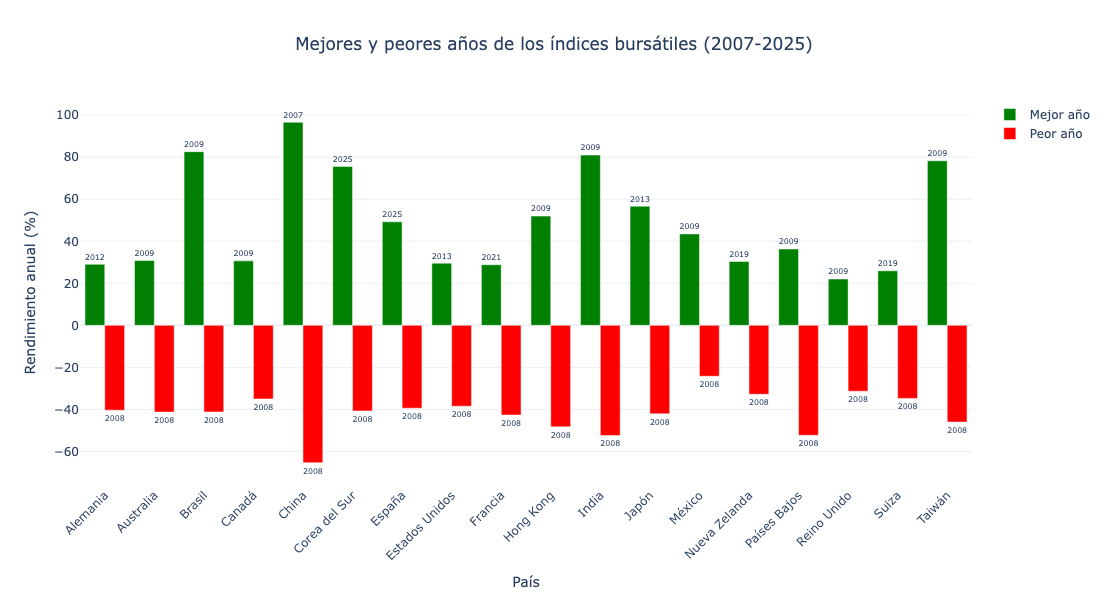

In [32]:
# Creo una copia de los rendimientos anuales.
df_grafico_anual = df_rendimientos_anuales.copy()

# Identifico los mejores y peores años de cada índice bursátil.
df_mejores_anios = df_grafico_anual.loc[
    df_grafico_anual.groupby("Ticker")["Rendimiento anual (%)"].idxmax()
].copy()

df_peores_anios = df_grafico_anual.loc[
    df_grafico_anual.groupby("Ticker")["Rendimiento anual (%)"].idxmin()
].copy()

# Creo un resumen para el gráfico.
df_resumen_anual = df_mejores_anios[
    ["País", "Índice", "Año", "Rendimiento anual (%)"]
].merge(
    df_peores_anios[
        ["País", "Índice", "Año", "Rendimiento anual (%)"]
    ],
    on=["País", "Índice"],
    suffixes=("_mejor", "_peor")
).sort_values("País")

# Creo un gráfico comparativo de los mejores y peores años.
fig = go.Figure()

# Agrego los rendimientos de los mejores años.
fig.add_trace(go.Bar(
    name="Mejor año",
    x=df_resumen_anual["País"],
    y=df_resumen_anual["Rendimiento anual (%)_mejor"],
    text=df_resumen_anual["Año_mejor"],
    textposition="outside",
    marker_color="green",
    hovertemplate="%{x}<br>Año: %{text}<br>Rendimiento: %{y:.2f}%<extra></extra>"
))

# Agrego los rendimientos de los peores años.
fig.add_trace(go.Bar(
    name="Peor año",
    x=df_resumen_anual["País"],
    y=df_resumen_anual["Rendimiento anual (%)_peor"],
    text=df_resumen_anual["Año_peor"],
    textposition="outside",
    marker_color="red",
    hovertemplate="%{x}<br>Año: %{text}<br>Rendimiento: %{y:.2f}%<extra></extra>"
))

# Configuro el gráfico original.
fig.update_layout(
    title="Mejores y peores años de los índices bursátiles (2007-2025)",
    title_x=0.5,
    xaxis_title="País",
    yaxis_title="Rendimiento anual (%)",
    barmode="group",
    height=600,
    template="plotly_white",
    xaxis_tickangle=-45,
    xaxis_categoryorder="array",
    xaxis_categoryarray=df_resumen_anual["País"].tolist()
)

# Muestro el gráfico.
fig.show()

> Al comparar los rendimientos anuales de los 18 índices bursátiles entre 2007 y 2025, observo que **2008 fue el peor año para todos los mercados analizados**, en coincidencia con la crisis financiera mundial. China registró una de las caídas más pronunciadas, con un rendimiento del −65,39 %. En cambio, los mejores años varían entre países, lo que muestra que los mercados no se recuperan ni crecen al mismo ritmo.

#### ¿Qué mercados bursátiles obtuvieron el mayor rendimiento acumulado durante los últimos 20 años?

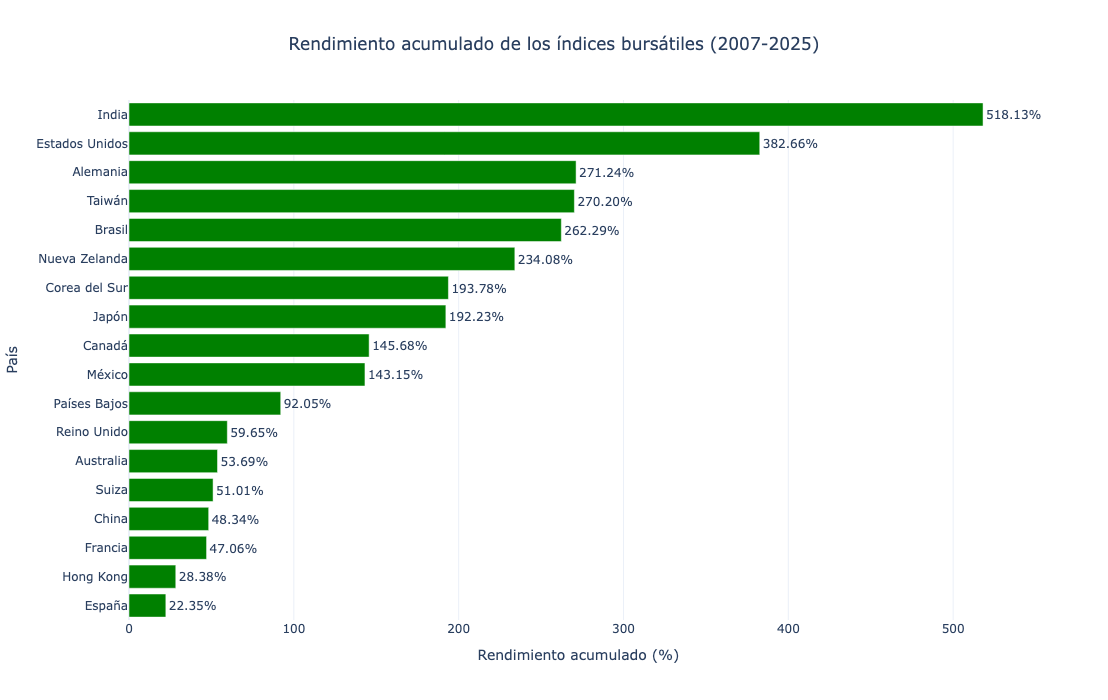

In [33]:
# Creo una copia de los rendimientos acumulados para el gráfico.
df_grafico_acumulado = df_rendimiento_acumulado.copy()

# Ordeno los países de mayor a menor rendimiento acumulado.
df_grafico_acumulado = df_grafico_acumulado.sort_values(
    "Rendimiento acumulado (%)", ascending=False
)

# Creo el gráfico comparativo del rendimiento acumulado.
fig = go.Figure()

# Agrego las barras con colores según el rendimiento.
fig.add_trace(go.Bar(
    x=df_grafico_acumulado["Rendimiento acumulado (%)"],
    y=df_grafico_acumulado["País"],
    orientation="h",
    marker_color=[
        "green" if valor >= 0 else "red"
        for valor in df_grafico_acumulado["Rendimiento acumulado (%)"]
    ],
    text=df_grafico_acumulado["Rendimiento acumulado (%)"].map(
        lambda valor: f"{valor:.2f}%"
    ),
    textposition="outside",
    cliponaxis=False,
    hovertemplate="%{y}<br>Rendimiento acumulado: %{x:.2f}%<extra></extra>"
))

# Configuro el gráfico original.
fig.update_layout(
    title="Rendimiento acumulado de los índices bursátiles (2007-2025)",
    title_x=0.5,
    xaxis_title="Rendimiento acumulado (%)",
    yaxis_title="País",
    height=700,
    template="plotly_white",
    yaxis_autorange="reversed",
    showlegend=False
)

# Muestro el gráfico.
fig.show()

> En el análisis del rendimiento acumulado entre 2007 y 2025, India se destaca con el mayor crecimiento (518,13 %), seguida por Estados Unidos (382,66 %). Por el contrario, España registra el menor rendimiento (22,35 %). Un caso interesante es China, que tuvo un crecimiento muy alto en 2007, pero terminó el período con un rendimiento acumulado de apenas 48,34 %. Estos resultados muestran que un buen desempeño en un año no garantiza un crecimiento sostenido a largo plazo.
>
> Es importante aclarar que estos porcentajes reflejan la variación de los índices en sus respectivas monedas y no tienen en cuenta los dividendos, la inflación ni las variaciones del tipo de cambio. Por eso, permiten comparar la evolución de los índices bursátiles, pero no representan necesariamente el rendimiento real que obtendría un inversor internacional.

#### ¿Los índices bursátiles de un mismo continente muestran tendencias similares?

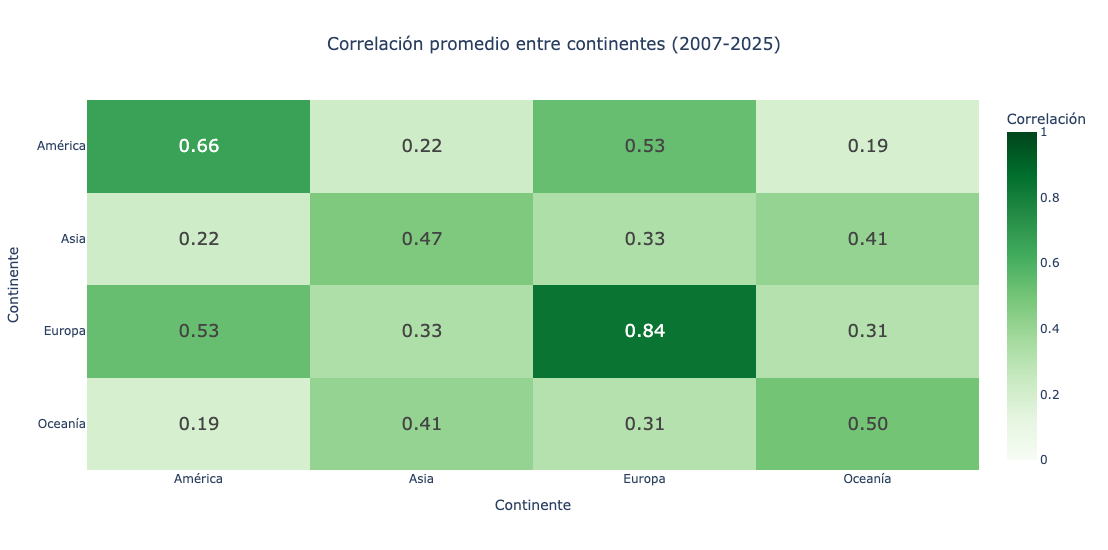

In [34]:
# Defino el continente de cada país.
continentes = {
    "Alemania": "Europa",
    "Australia": "Oceanía",
    "Brasil": "América",
    "Canadá": "América",
    "China": "Asia",
    "Corea del Sur": "Asia",
    "España": "Europa",
    "Estados Unidos": "América",
    "Francia": "Europa",
    "Hong Kong": "Asia",
    "India": "Asia",
    "Japón": "Asia",
    "México": "América",
    "Nueva Zelanda": "Oceanía",
    "Países Bajos": "Europa",
    "Reino Unido": "Europa",
    "Suiza": "Europa",
    "Taiwán": "Asia"
}

# Creo una copia de las correlaciones calculadas en Gold.
df_correlaciones_continentes = df_correlaciones.copy()

# Calculo la correlación promedio dentro de cada continente y entre continentes.
regiones = ["América", "Asia", "Europa", "Oceanía"]
matriz = []

for region_1 in regiones:
    fila = []

    for region_2 in regiones:
        paises_1 = [
            pais for pais in df_correlaciones_continentes.index
            if continentes[pais] == region_1
        ]
        paises_2 = [
            pais for pais in df_correlaciones_continentes.columns
            if continentes[pais] == region_2
        ]

        valores = [
            df_correlaciones_continentes.loc[pais_1, pais_2]
            for pais_1 in paises_1
            for pais_2 in paises_2
            if pais_1 != pais_2
        ]

        fila.append(round(sum(valores) / len(valores), 2))

    matriz.append(fila)

# Creo el mapa de calor con tonos verdes según la correlación.
fig = go.Figure(go.Heatmap(
    z=matriz,
    x=regiones,
    y=regiones,
    colorscale="Greens",
    zmin=0,
    zmax=1,
    text=matriz,
    texttemplate="%{text:.2f}",
    textfont=dict(size=18),
    colorbar=dict(title="Correlación"),
    hovertemplate="%{y} / %{x}<br>Correlación: %{z:.2f}<extra></extra>"
))

# Configuro el gráfico.
fig.update_layout(
    title="Correlación promedio entre continentes (2007-2025)",
    title_x=0.5,
    xaxis_title="Continente",
    yaxis_title="Continente",
    height=550,
    template="plotly_white",
    yaxis_autorange="reversed"
)

# Muestro el gráfico.
fig.show()

> Los resultados muestran que Europa tiene la mayor correlación promedio entre sus índices bursátiles (0,84), seguida por América (0,66). Esto indica que los mercados europeos tienden a moverse de manera más similar entre sí. Por otro lado, Oceanía (0,50) y Asia (0,47) presentan valores muy parecidos, con una relación moderada entre los movimientos de sus índices.
>
> Es importante aclarar que en Oceanía solo analizo dos mercados, Australia y Nueva Zelanda, por lo que el resultado es menos representativo. En general, observo que los índices de un mismo continente pueden seguir tendencias similares, aunque esto no significa que tengan los mismos rendimientos.

#### ¿Qué diferencias existen entre los mercados bursátiles de países desarrollados y emergentes?

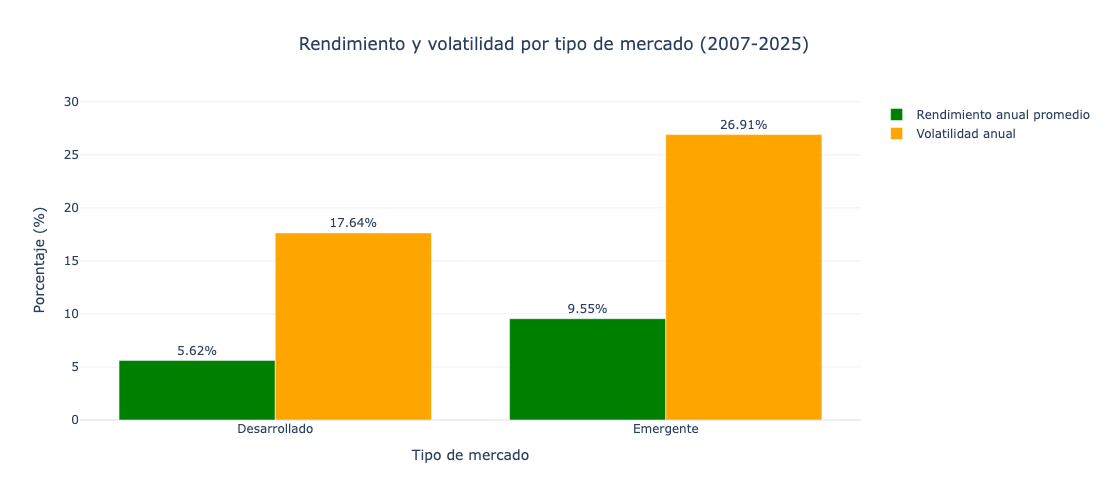

In [35]:
# Creo una copia de los indicadores de mercados desarrollados y emergentes.
df_grafico_mercados = df_resumen_mercados.copy()

# Creo un gráfico para comparar el rendimiento y la volatilidad.
fig = go.Figure()

# Agrego el rendimiento anual promedio de cada grupo.
fig.add_trace(go.Bar(
    name="Rendimiento anual promedio",
    x=df_grafico_mercados["Mercado"],
    y=df_grafico_mercados["Rendimiento anual promedio (%)"],
    marker_color="green",
    text=df_grafico_mercados["Rendimiento anual promedio (%)"].map(
        lambda valor: f"{valor:.2f}%"
    ),
    textposition="outside"
))

# Agrego la volatilidad anual de cada grupo.
fig.add_trace(go.Bar(
    name="Volatilidad anual",
    x=df_grafico_mercados["Mercado"],
    y=df_grafico_mercados["Volatilidad anual promedio (%)"],
    marker_color="orange",
    text=df_grafico_mercados["Volatilidad anual promedio (%)"].map(
        lambda valor: f"{valor:.2f}%"
    ),
    textposition="outside"
))

# Configuro el gráfico.
fig.update_layout(
    title="Rendimiento y volatilidad por tipo de mercado (2007-2025)",
    title_x=0.5,
    xaxis_title="Tipo de mercado",
    yaxis_title="Porcentaje (%)",
    barmode="group",
    height=500,
    template="plotly_white"
)

# Muestro el gráfico.
fig.show()

> Los mercados emergentes presentan un rendimiento anual promedio mayor (9,55 %) que los desarrollados (5,62 %). Sin embargo, también muestran una volatilidad más alta (26,91 % frente a 17,64 %), lo que significa que sus resultados cambian más de un año a otro. Esto sugiere que los mercados emergentes ofrecen un mayor potencial de crecimiento, pero también presentan más incertidumbre. De todos modos, esta comparación se basa en los índices seleccionados y en sus rendimientos históricos, por lo que no garantiza que esta relación se mantenga en el futuro.

#### ¿Cuáles son los mercados bursátiles que muestran una tendencia de crecimiento más favorable en los últimos años?

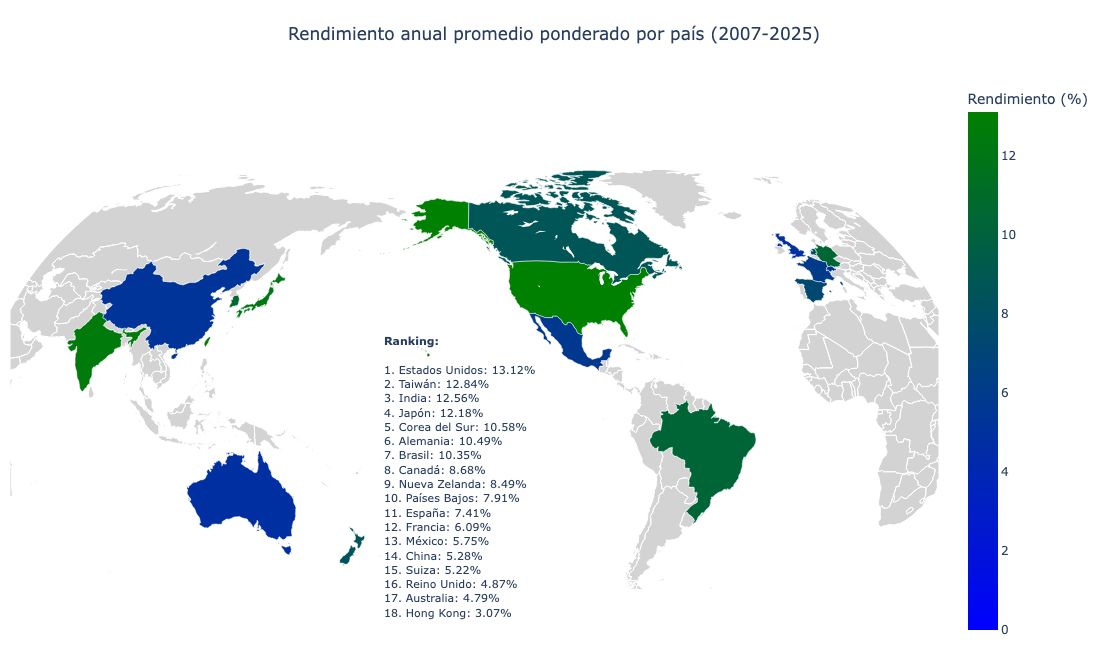

In [36]:
# Defino los códigos internacionales de los 18 países.
codigos_paises = {
    "Alemania": "DEU",
    "Australia": "AUS",
    "Brasil": "BRA",
    "Canadá": "CAN",
    "China": "CHN",
    "Corea del Sur": "KOR",
    "España": "ESP",
    "Estados Unidos": "USA",
    "Francia": "FRA",
    "Hong Kong": "HKG",
    "India": "IND",
    "Japón": "JPN",
    "México": "MEX",
    "Nueva Zelanda": "NZL",
    "Países Bajos": "NLD",
    "Reino Unido": "GBR",
    "Suiza": "CHE",
    "Taiwán": "TWN"
}

# Creo una copia y ordeno los países por rendimiento ponderado.
df_ranking_ponderado = df_tendencia_reciente.copy()
df_ranking_ponderado = df_ranking_ponderado.sort_values(
    "Rendimiento ponderado (%)", ascending=False
).reset_index(drop=True)

# Creo el planisferio con el rendimiento ponderado de cada país.
fig = go.Figure(go.Choropleth(
    locations=df_ranking_ponderado["País"].map(codigos_paises),
    z=df_ranking_ponderado["Rendimiento ponderado (%)"],
    customdata=df_ranking_ponderado["País"],
    locationmode="ISO-3",
    colorscale=[[0, "blue"], [1, "green"]],
    zmin=0,
    zmax=df_ranking_ponderado["Rendimiento ponderado (%)"].max(),
    marker_line_color="white",
    marker_line_width=0.5,
    colorbar_title="Rendimiento (%)",
    hovertemplate="País: %{customdata}<br>Rendimiento anual promedio ponderado: %{z:.2f}%<extra></extra>"
))

# Configuro el planisferio.
fig.update_geos(
    projection_type="natural earth",
    showcoastlines=False,
    showcountries=True,
    countrycolor="white",
    showland=True,
    landcolor="lightgray",
    showframe=False
)

# Agrego el ranking en el espacio izquierdo del gráfico.
fig.add_annotation(
    x=0.40,
    y=0.55,
    xref="paper",
    yref="paper",
    text="<b>Ranking:</b><br><br>" + "<br>".join(
        f"{posicion + 1}. {fila['País']}: {fila['Rendimiento ponderado (%)']:.2f}%"
        for posicion, fila in df_ranking_ponderado.iterrows()
    ),
    showarrow=False,
    xanchor="left",
    yanchor="top",
    align="left",
    font=dict(size=11)
)

fig.update_layout(
    title="Rendimiento anual promedio ponderado por país (2007-2025)",
    title_x=0.5,
    height=650,
    dragmode=False,
    margin=dict(b=10, l=10, r=10, t=80),
    template="plotly_white"
)

# Muestro el planisferio sin permitir zoom.
fig.show(config={
    "scrollZoom": False,
    "modeBarButtonsToRemove": ["zoomInGeo", "zoomOutGeo", "resetGeo"]
})

> Al analizar los rendimientos anuales y dar mayor importancia a los años recientes, observo que Estados Unidos encabeza el ranking con un 13,12 %, seguido por Taiwán (12,84 %) e India (12,56 %). En cambio, Hong Kong presenta el valor más bajo (3,07 %). Me llama la atención que India, que lideraba el rendimiento acumulado, ahora ocupa el tercer puesto. Esto muestra que los resultados cambian según la forma en que se mide el crecimiento.
>
> También es importante aclarar que este indicador considera todo el período 2007-2025, aunque asigna más peso a los años recientes, por lo que no representa exclusivamente el rendimiento de los últimos años ni permite predecir resultados futuros.

#### ¿Existen patrones estacionales en el volumen de operaciones bursátiles?

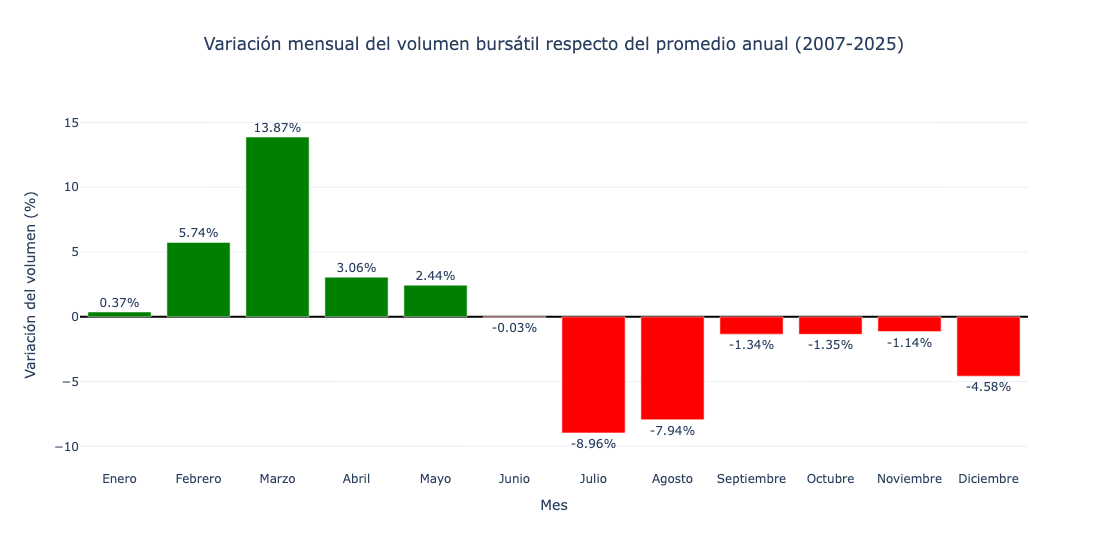

In [37]:
# Creo un gráfico de barras con la variación mensual del volumen de operaciones.
fig = go.Figure()

# Agrego las barras con colores según la variación del volumen.
fig.add_trace(go.Bar(
    x=df_resumen_volumen["Mes"],
    y=df_resumen_volumen["Variación del volumen (%)"],
    marker_color=[
        "green" if valor >= 0 else "red"
        for valor in df_resumen_volumen["Variación del volumen (%)"]
    ],
    text=df_resumen_volumen["Variación del volumen (%)"].map(
        lambda valor: f"{valor:.2f}%"
    ),
    textposition="outside",
    customdata=df_resumen_frecuencia_volumen["Frecuencia de menor actividad (%)"],
    hovertemplate="Mes: %{x}<br>Variación del volumen: %{y:.2f}%<br>Frecuencia de menor actividad: %{customdata:.2f}%<extra></extra>"
))

# Configuro el gráfico original.
fig.update_layout(
    title="Variación mensual del volumen bursátil respecto del promedio anual (2007-2025)",
    title_x=0.5,
    xaxis_title="Mes",
    yaxis_title="Variación del volumen (%)",
    height=550,
    template="plotly_white",
    showlegend=False,
    yaxis_zeroline=True,
    yaxis_zerolinecolor="black"
)

# Muestro el gráfico.
fig.show()

> Los resultados muestran una mayor actividad bursátil durante los primeros meses del año, especialmente en marzo (+13,87 %), y una disminución en julio (−8,96 %) y agosto (−7,94 %). Una posible explicación es que durante julio y agosto coinciden las vacaciones de verano en muchos países del hemisferio norte, lo que puede reducir la participación de inversores y operadores. Sin embargo, esta es una hipótesis, ya que los datos analizados no permiten confirmar las causas de estas variaciones.

## Conclusiones generales:

> En este trabajo analicé 18 índices bursátiles de distintos países, tomando como referencia los últimos 20 años, desde 2006 hasta 2026. Para comparar los rendimientos anuales, decidí trabajar con el período 2007-2025, porque 2006 y 2026 tenían datos parciales. De esta manera, pude comparar años completos y obtener resultados más consistentes, sin dejar de considerar los 20 años de información que descargué.
>
> Uno de los resultados que más me llamó la atención fue el impacto de la crisis financiera de 2008, ya que todos los índices analizados registraron su peor rendimiento anual en ese año. También encontré diferencias importantes en el crecimiento a largo plazo: India y Estados Unidos tuvieron rendimientos acumulados muy superiores a los de otros mercados, como España y China.
>
> Por otro lado, observé que los índices de un mismo continente no siempre se comportan de la misma manera. Europa presentó la mayor correlación entre sus mercados, mientras que Asia y Oceanía mostraron movimientos menos similares. También comprobé que los mercados emergentes tuvieron un mayor rendimiento anual promedio que los desarrollados, pero con una volatilidad más alta. Esto demuestra que un mayor crecimiento también puede estar acompañado de mayores variaciones en los resultados.
>
> Otro punto interesante fue encontrar diferencias en el volumen de operaciones según el mes del año. Marzo presentó la mayor actividad, mientras que julio y agosto tuvieron los valores más bajos. Esto podría estar relacionado con las vacaciones de verano en varios países del hemisferio norte, aunque los datos no permiten asegurar que esa sea la causa.
>
> Para realizar todo el trabajo, organicé los datos mediante la arquitectura Medallion, con las capas Bronze, Silver y Gold. Esto me permitió separar la descarga de información, la limpieza de los datos y la preparación de los indicadores que después usé en los gráficos. También tuve que tomar algunas decisiones, como excluir Australia del análisis de volumen porque tenía demasiados registros sin información válida.
>
> Finalmente, considero importante aclarar que los rendimientos están expresados en las monedas de cada mercado y no contemplan dividendos, inflación ni variaciones del tipo de cambio. Por eso, los resultados sirven para estudiar y comparar la evolución histórica de los índices, pero no representan necesariamente las ganancias reales de una inversión.
>
> En general, este trabajo me permitió entender mejor cómo se comportaron los distintos mercados bursátiles durante estas dos décadas y comprobar que, para sacar conclusiones, es importante analizar varios indicadores y no quedarse solamente con cuánto subió o bajó un índice.

---

> En lo personal, disfruté mucho hacer este trabajo porque pude analizar un tema que me interesa y trabajar con datos reales de los mercados bursátiles. Lo que más me gustó fue aplicar la arquitectura Medallion. No la había usado antes y me pareció una forma muy cómoda y ordenada de trabajar, tanto que pienso seguir usándola en mis próximos proyectos. También me gustó ir descubriendo cosas a medida que avanzaba, especialmente cuando empecé a ver los resultados en los gráficos. Fue un trabajo que disfruté mucho y con el que aprendí bastante.